1. Import libraries and load the graph
The Karate Club graph contains 34 nodes and 78 edges. Each node represents a club member and each edge represents a recorded friendship.

In [1]:
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt

G = nx.karate_club_graph()

print("Number of nodes:", G.number_of_nodes())
print("Number of edges:", G.number_of_edges())

Number of nodes: 34
Number of edges: 78


2. Visualize the original graph
A fixed spring layout is used so that node positions remain consistent in every visualization.

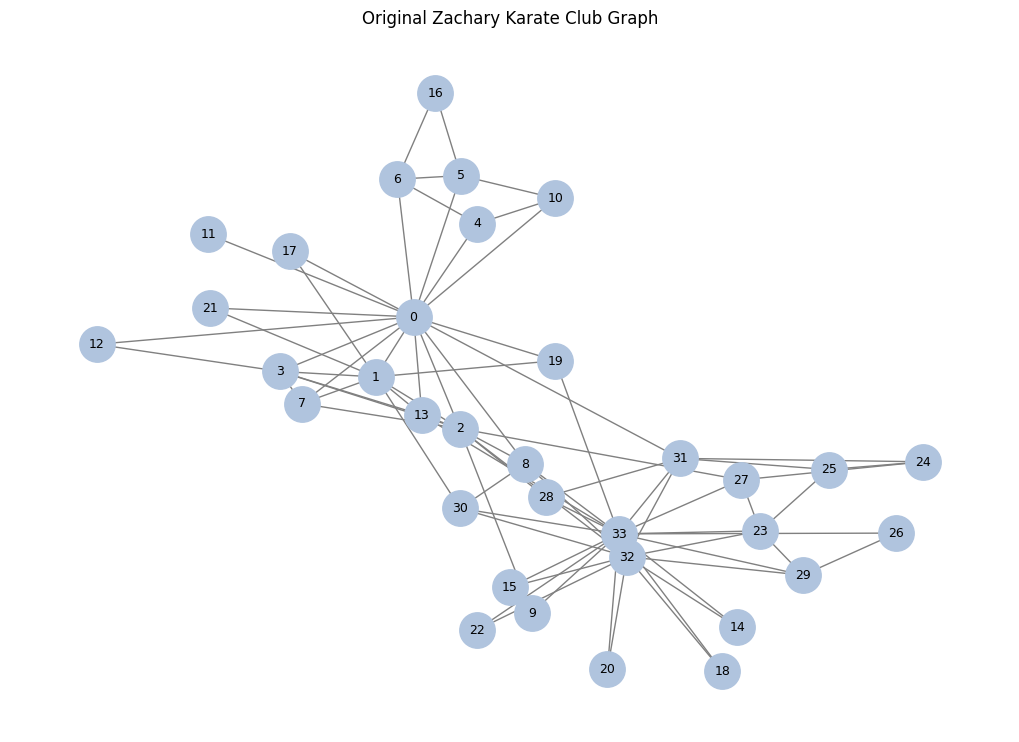

In [2]:
pos = nx.spring_layout(G, seed=42)

plt.figure(figsize=(10, 7))
nx.draw(
    G,
    pos,
    with_labels=True,
    node_size=650,
    node_color="lightsteelblue",
    edge_color="gray",
    font_size=9
)
plt.title("Original Zachary Karate Club Graph")
plt.axis("off")
plt.show()

3. Construct the adjacency matrix and modularity matrix


In [3]:
A = nx.to_numpy_array(G, dtype=float)
k = A.sum(axis=1)
m = G.number_of_edges()

B = A - np.outer(k, k) / (2 * m)

print("Adjacency matrix shape:", A.shape)
print("Degree vector shape:", k.shape)
print("Number of edges m:", m)
print("Modularity matrix shape:", B.shape)

# B should be symmetric for an undirected graph.
print("Is B symmetric?", np.allclose(B, B.T))

Adjacency matrix shape: (34, 34)
Degree vector shape: (34,)
Number of edges m: 78
Modularity matrix shape: (34, 34)
Is B symmetric? True


4. Recursive spectral modularity partitioning
For each current community:
    1. Extract its restricted modularity matrix from the original B.
    2. Find its largest eigenvalue and corresponding eigenvector.
    3. Stop if the largest eigenvalue is nonpositive.
    4. Otherwise, split nodes according to the signs of the eigenvector entries.
    5. Repeat recursively on both resulting groups.
A small numerical tolerance is used to avoid treating floating-point round-off near zero as a positive eigenvalue.

In [4]:
communities = [list(G.nodes())]
split_history = []
split_eigenvalues = []

def recursive_split(nodes):
    # Restricted block of the original global modularity matrix
    B_sub = B[np.ix_(nodes, nodes)]

    # B_sub is symmetric, so use eigh
    eigenvalues, eigenvectors = np.linalg.eigh(B_sub)

    index = np.argmax(eigenvalues)
    largest_eigenvalue = float(eigenvalues[index])
    leading_eigenvector = eigenvectors[:, index]

    # Stop when no positive-eigenvalue split is available
    if largest_eigenvalue <= 1e-10:
        return

    group1 = [
        nodes[i] for i, value in enumerate(leading_eigenvector)
        if value > 0
    ]
    group2 = [
        nodes[i] for i, value in enumerate(leading_eigenvector)
        if value <= 0
    ]

    # Avoid an invalid split if one side is empty
    if len(group1) == 0 or len(group2) == 0:
        return

    # Replace the current community with its two children
    communities.remove(nodes)
    communities.extend([group1, group2])

    split_eigenvalues.append(largest_eigenvalue)
    split_history.append([community.copy() for community in communities])

    # Recursively test both new communities
    recursive_split(group1)
    recursive_split(group2)


recursive_split(list(G.nodes()))

print("Number of splits:", len(split_history))
print("Number of final communities:", len(communities))
print("\nFinal communities:")
for i, community in enumerate(communities, start=1):
    print(f"Community {i} ({len(community)} nodes): {sorted(community)}")

Number of splits: 12
Number of final communities: 13

Final communities:
Community 1 (2 nodes): [26, 29]
Community 2 (2 nodes): [8, 30]
Community 3 (3 nodes): [14, 20, 32]
Community 4 (1 nodes): [15]
Community 5 (4 nodes): [9, 18, 22, 33]
Community 6 (4 nodes): [24, 25, 28, 31]
Community 7 (2 nodes): [23, 27]
Community 8 (1 nodes): [2]
Community 9 (3 nodes): [1, 19, 21]
Community 10 (1 nodes): [13]
Community 11 (3 nodes): [3, 7, 12]
Community 12 (3 nodes): [0, 11, 17]
Community 13 (5 nodes): [4, 5, 6, 10, 16]


5. Visualize the graph after every split
The same spring-layout positions are reused. Each current community receives a different colour, and nodes retain their original IDs.

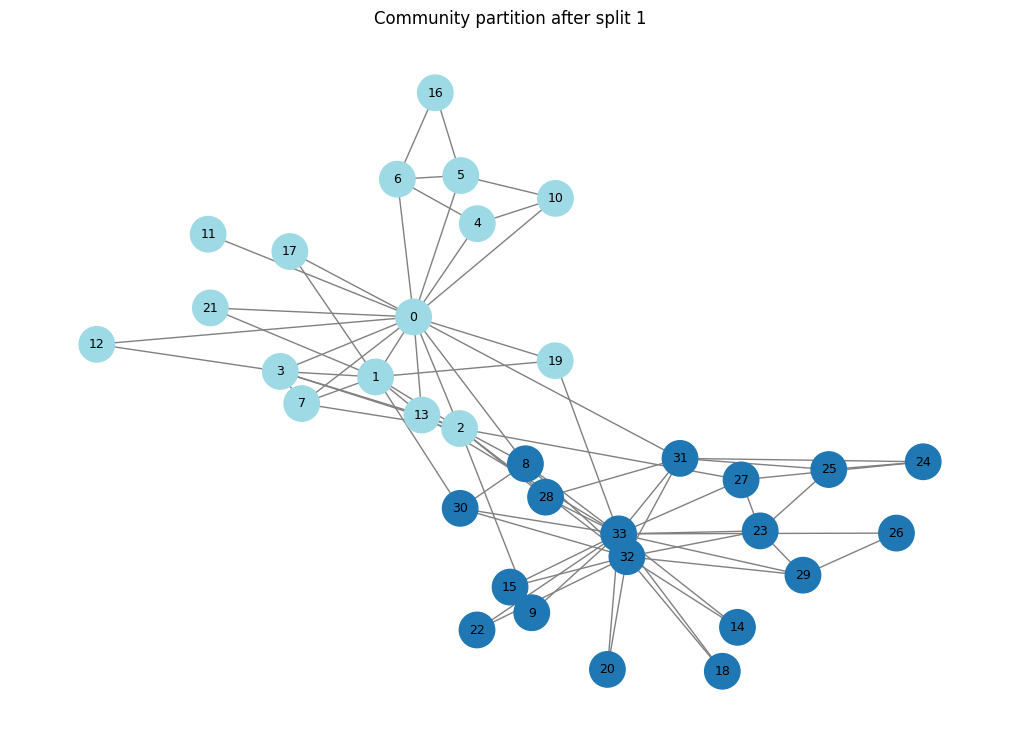

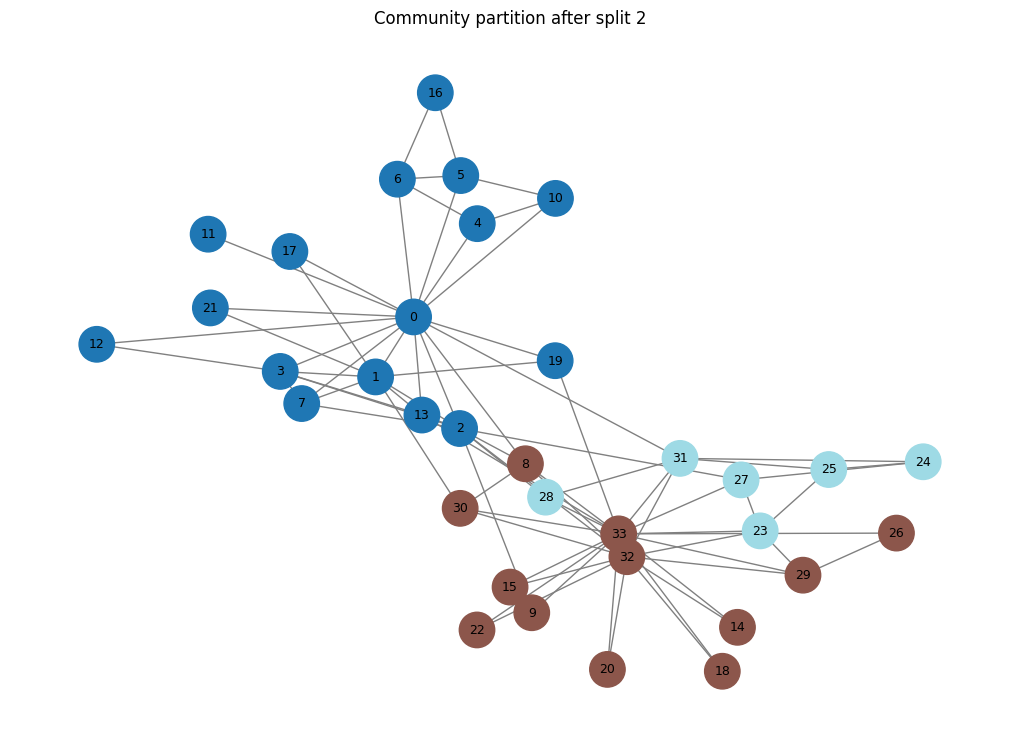

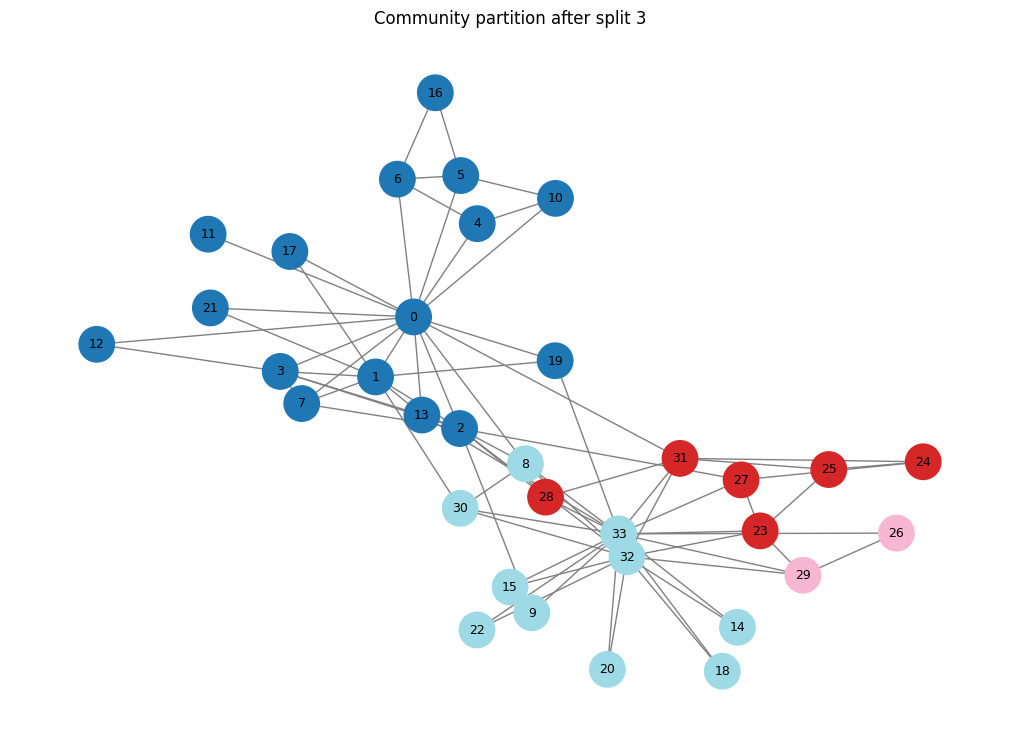

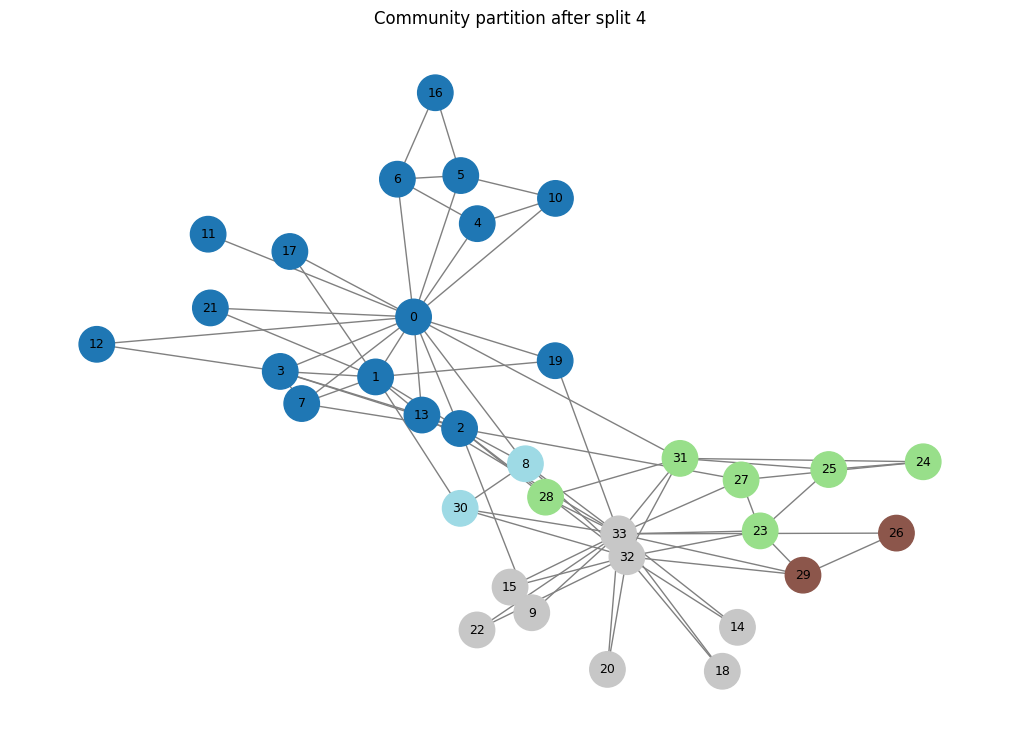

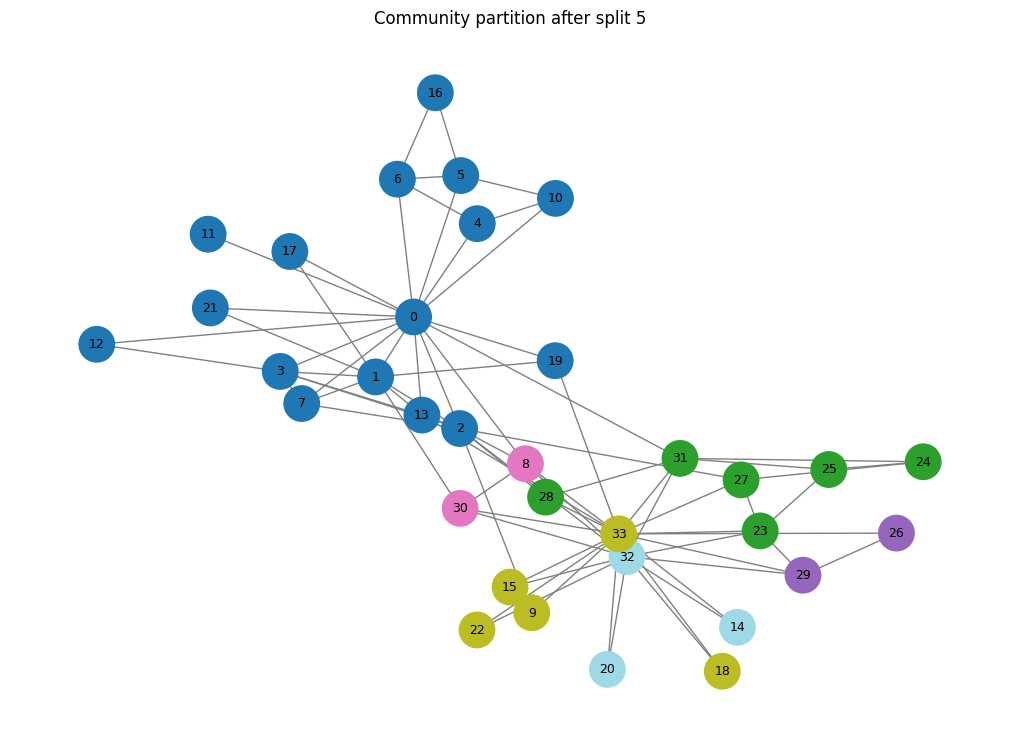

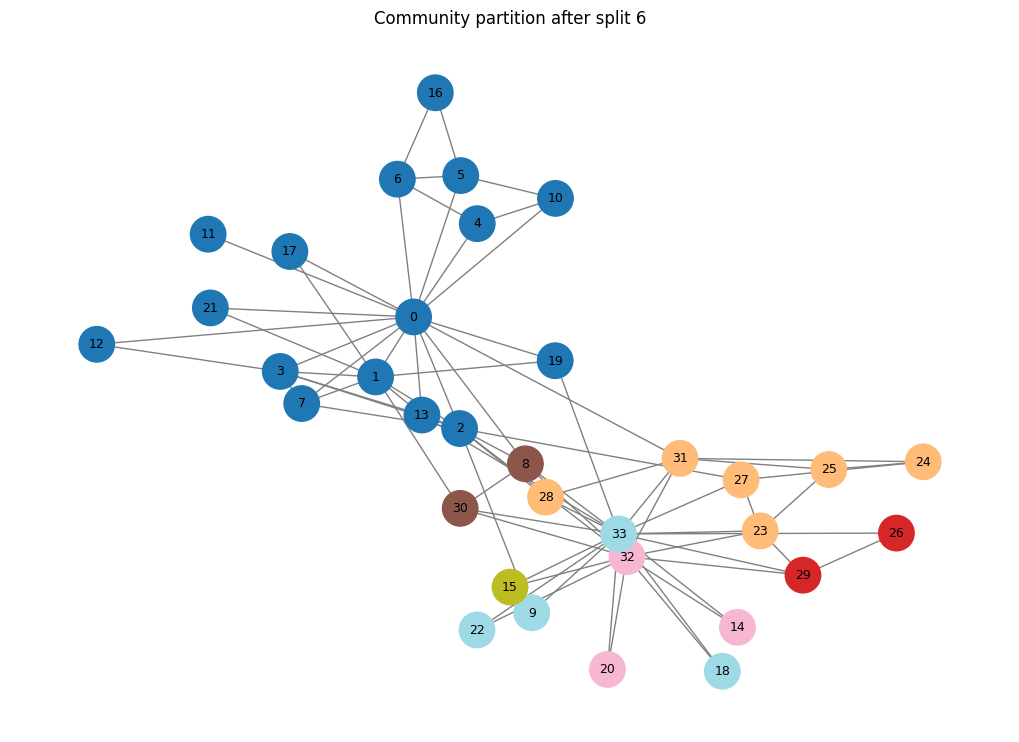

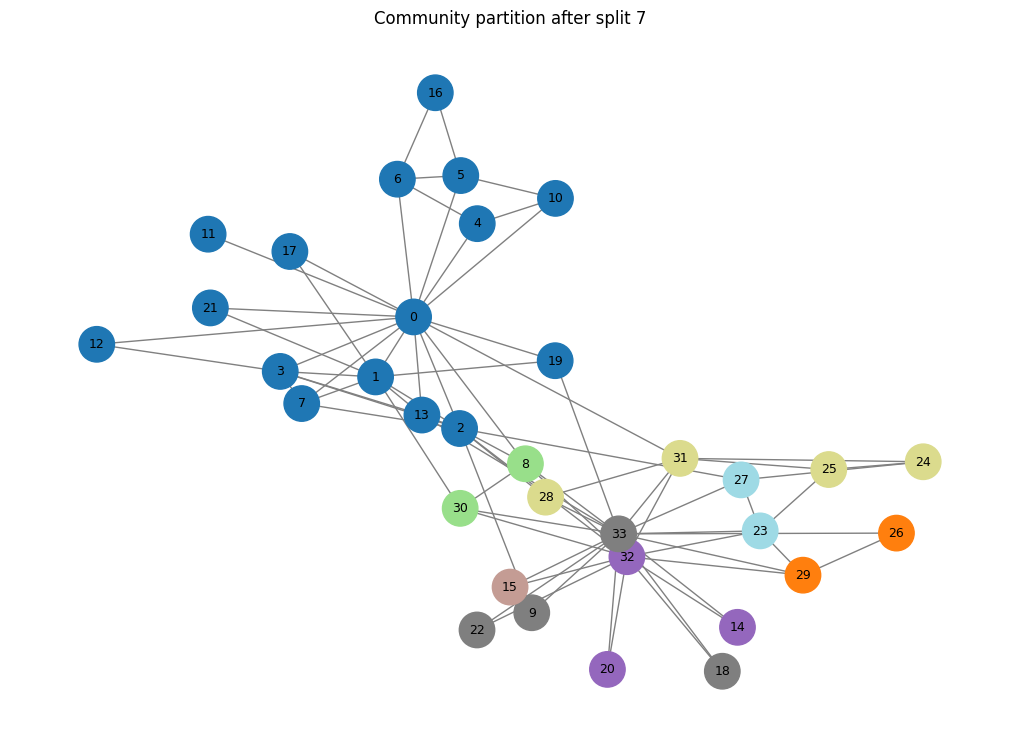

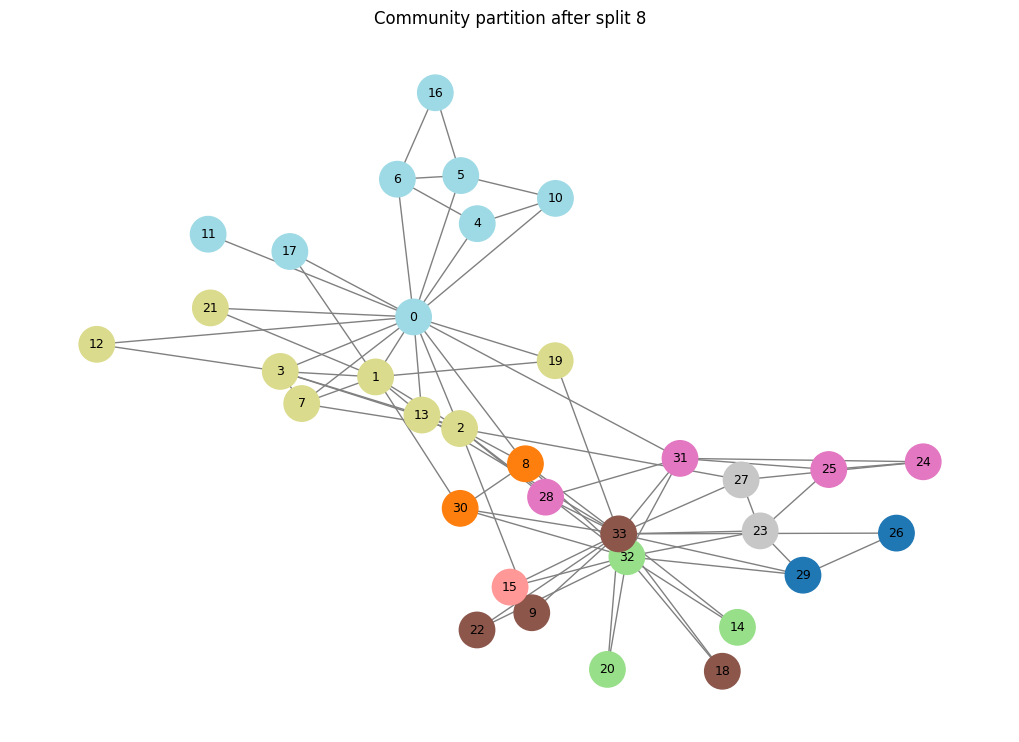

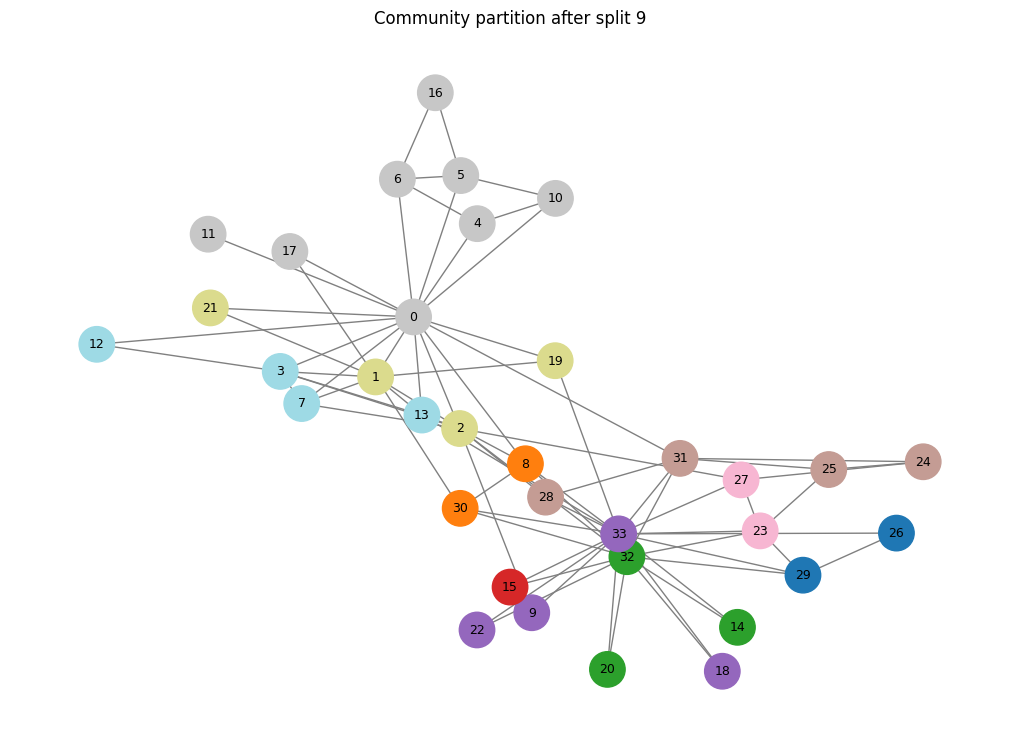

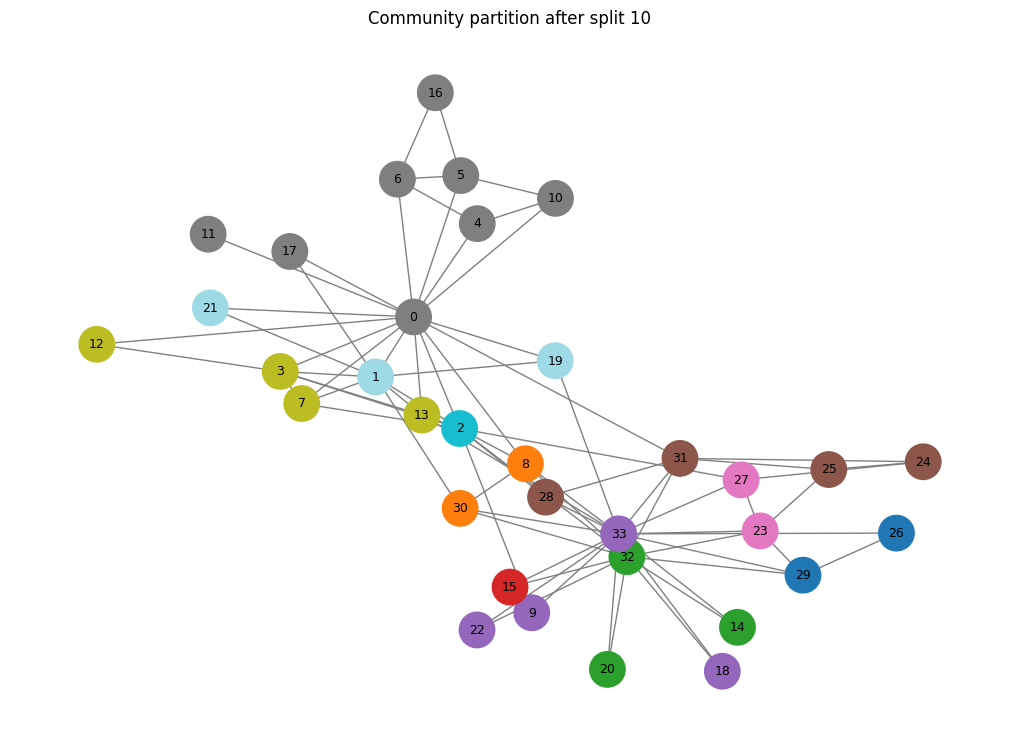

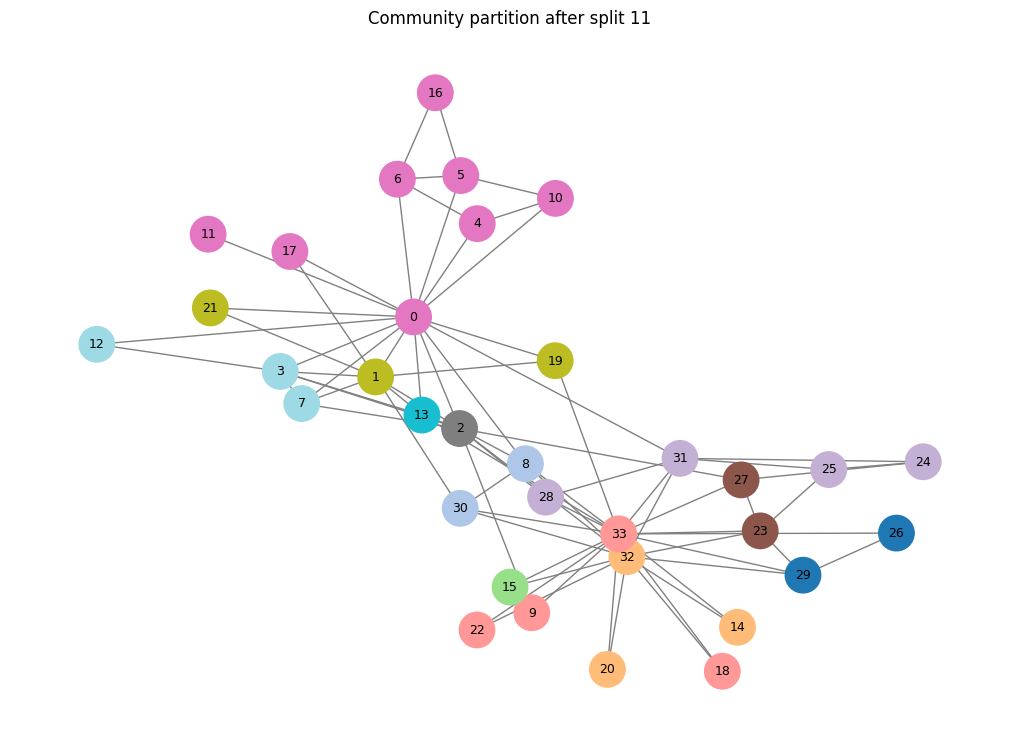

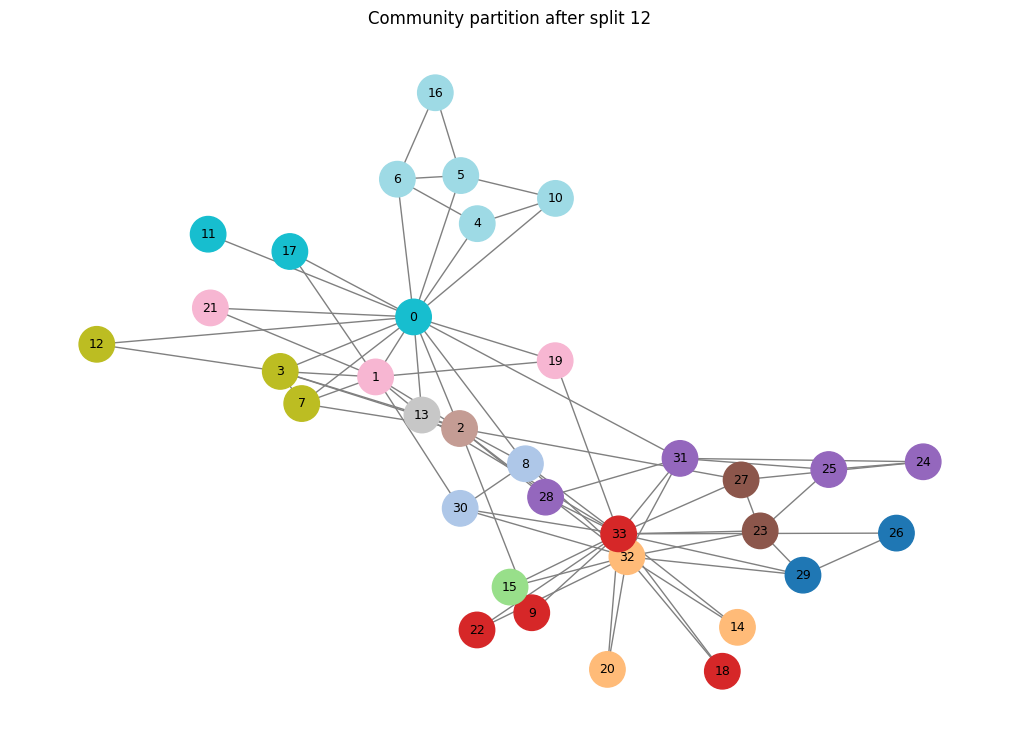

In [5]:
for iteration, partition in enumerate(split_history, start=1):
    node_community = {}

    for community_id, community in enumerate(partition):
        for node in community:
            node_community[node] = community_id

    node_colours = [
        node_community[node] for node in G.nodes()
    ]

    plt.figure(figsize=(10, 7))
    nx.draw(
        G,
        pos,
        with_labels=True,
        node_size=650,
        node_color=node_colours,
        cmap=plt.cm.tab20,
        edge_color="gray",
        font_size=9
    )
    plt.title(f"Community partition after split {iteration}")
    plt.axis("off")
    plt.show()

6. Calculate network metrics after each split
For each snapshot, the four metrics are calculated on the induced subgraph of the community to which each node currently belongs. This makes the values reflect how a node's local position changes as its community is subdivided.

The metrics are:
- Degree centrality
- Betweenness centrality
- Closeness centrality
- Clustering coefficient
The initial unsplit graph is also stored as iteration 0, so the plots show the change from the original network.

In [6]:
metric_names = [
    "Degree centrality",
    "Betweenness centrality",
    "Closeness centrality",
    "Clustering coefficient"
]

def calculate_metrics(partition):
    # Prepare a value for every node for every metric
    snapshot = {
        metric: {node: np.nan for node in G.nodes()}
        for metric in metric_names
    }

    for community in partition:
        H = G.subgraph(community).copy()

        values = {
            "Degree centrality": nx.degree_centrality(H),
            "Betweenness centrality": nx.betweenness_centrality(H),
            "Closeness centrality": nx.closeness_centrality(H),
            "Clustering coefficient": nx.clustering(H)
        }

        for metric in metric_names:
            snapshot[metric].update(values[metric])

    return snapshot


# Iteration 0: before any split
metric_history = [
    calculate_metrics([list(G.nodes())])
]

# Store metrics after every split
for partition in split_history:
    metric_history.append(calculate_metrics(partition))

print("Metric snapshots stored:", len(metric_history))
print("Nodes measured in each snapshot:", G.number_of_nodes())

Metric snapshots stored: 13
Nodes measured in each snapshot: 34


7. Plot the evolution of each metric
Each line represents one node. The x-axis is the iteration number: 0 is the original graph, and later values are after successive splits

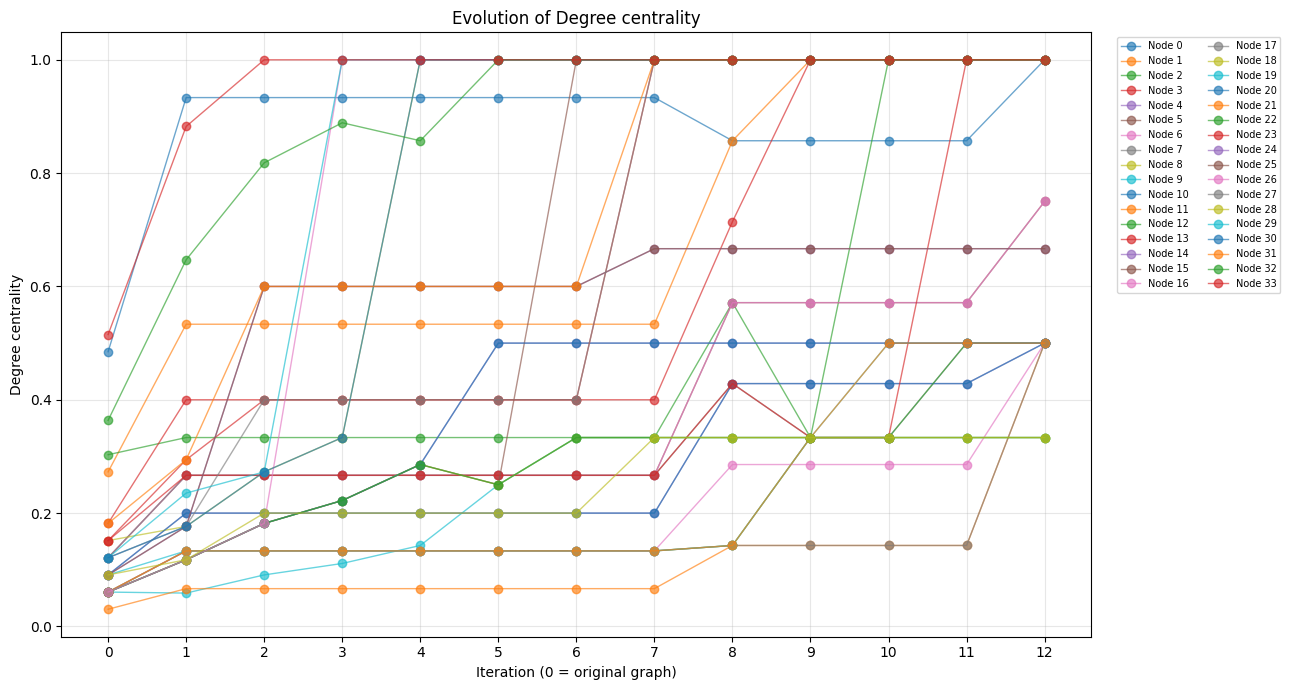

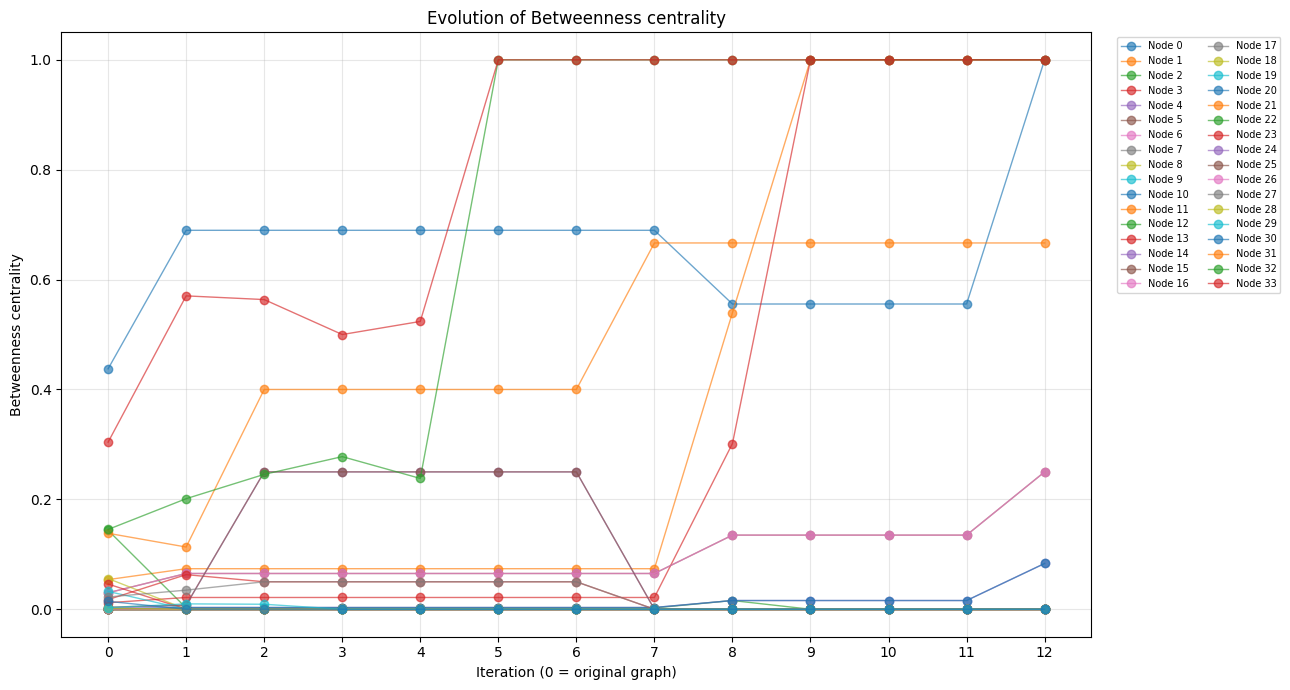

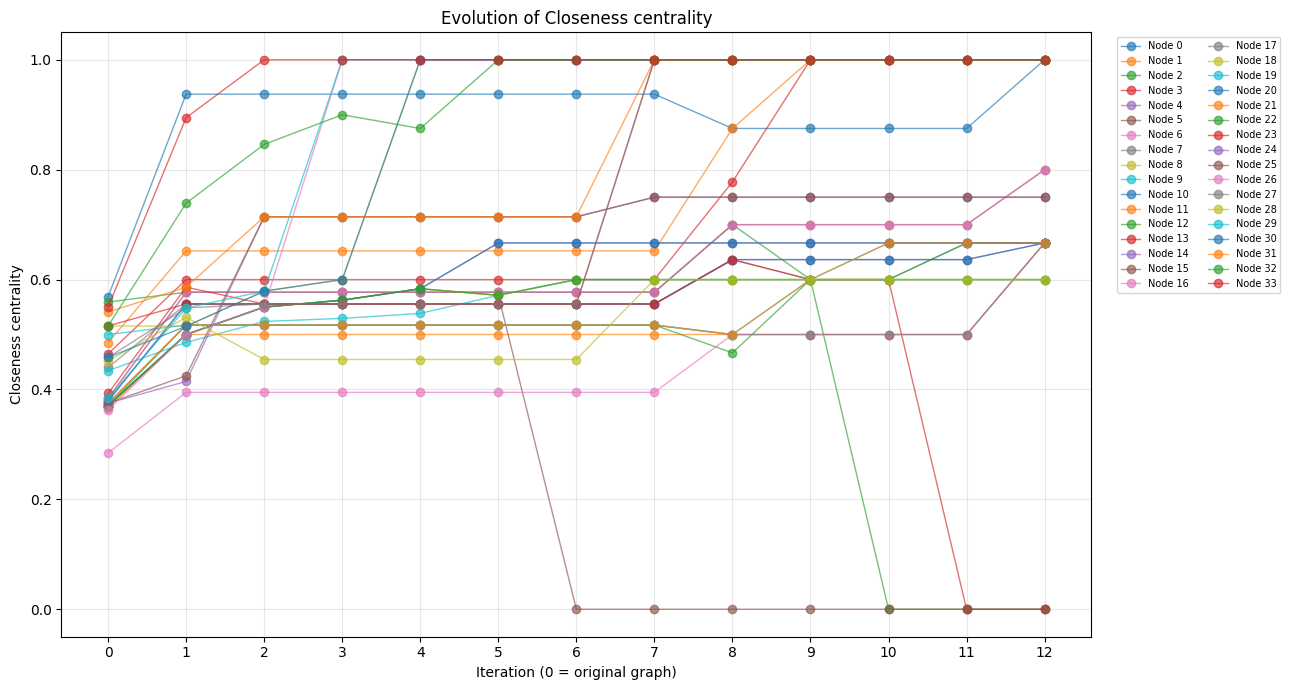

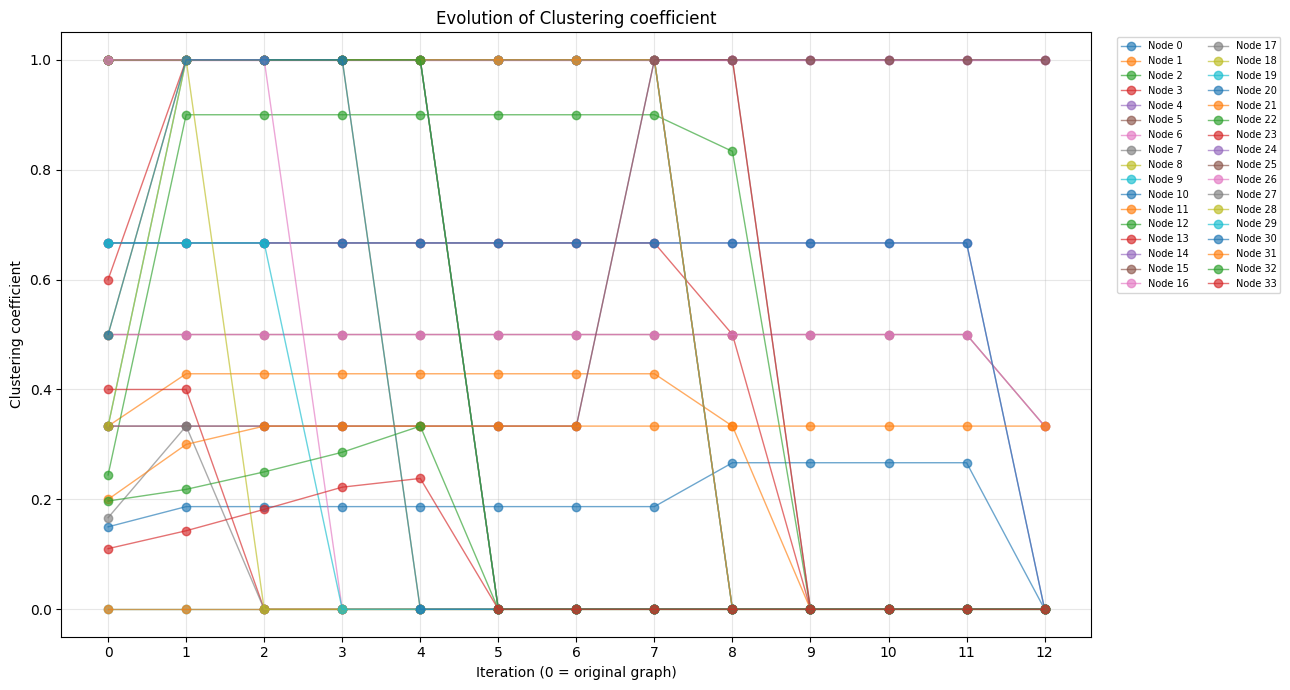

In [7]:
iterations = list(range(len(metric_history)))
nodes = list(G.nodes())

for metric in metric_names:
    plt.figure(figsize=(13, 7))

    for node in nodes:
        values = [
            snapshot[metric][node]
            for snapshot in metric_history
        ]
        plt.plot(iterations, values, marker="o", linewidth=1, alpha=0.65,
                 label=f"Node {node}")

    plt.title(f"Evolution of {metric}")
    plt.xlabel("Iteration (0 = original graph)")
    plt.ylabel(metric)
    plt.xticks(iterations)
    plt.grid(alpha=0.3)
    plt.legend(
        bbox_to_anchor=(1.02, 1),
        loc="upper left",
        ncol=2,
        fontsize=7
    )
    plt.tight_layout()
    plt.show()

8. Identify nodes that frequently rank highly
The following analysis counts how often each node appears in the top five for each metric across the stored iterations. It helps identify nodes that remain relatively central as communities are split.

In [8]:
top_k = 5

for metric in metric_names:
    top_frequencies = {node: 0 for node in G.nodes()}

    for snapshot in metric_history:
        ranked_nodes = sorted(
            snapshot[metric].items(),
            key=lambda item: item[1],
            reverse=True
        )
        for node, value in ranked_nodes[:top_k]:
            top_frequencies[node] += 1

    ranked_frequency = sorted(
        top_frequencies.items(),
        key=lambda item: item[1],
        reverse=True
    )

    print(f"\n{metric}:")
    print("Node : number of snapshots in top five")
    for node, count in ranked_frequency[:10]:
        print(f"{node:>4} : {count}")


Degree centrality:
Node : number of snapshots in top five
   8 : 9
   1 : 6
  26 : 6
   0 : 5
   3 : 5
  15 : 5
  32 : 5
  33 : 5
   2 : 4
  29 : 4

Betweenness centrality:
Node : number of snapshots in top five
  33 : 13
  31 : 12
  32 : 11
   0 : 10
   1 : 7
  24 : 5
   3 : 4
  25 : 2
   2 : 1
   4 : 0

Closeness centrality:
Node : number of snapshots in top five
   8 : 10
  26 : 9
  23 : 6
  29 : 6
   0 : 5
   1 : 5
   3 : 5
  32 : 5
  33 : 5
  30 : 3

Clustering coefficient:
Node : number of snapshots in top five
   7 : 9
  16 : 9
  12 : 8
  13 : 8
  14 : 5
  24 : 5
  25 : 5
   4 : 3
   8 : 3
  10 : 3


9. Calculate the modularity of the final partition

In [9]:
final_modularity = 0.0

for community in communities:
    B_community = B[np.ix_(community, community)]
    final_modularity += B_community.sum()

final_modularity /= (2 * m)

print("Modularity of final partition:", final_modularity)

Modularity of final partition: 0.12557527942143326
